# 02 · Synthetic households (v2)

This notebook creates the **rows** of the matrix: 5,000 simulated households, and for each one

1. its **household facts** (number of smart devices, household size, age band, children),
2. its **attitudes**: six general traits plus **its own attitude to each of the 8 purposes**,
3. its **decision on every item** from notebook 01 (computed, nobody is asked anything),
4. its **answers to 27 candidate onboarding questions** (computed from the same household, plus noise).

Later notebooks cluster the decisions (→ presets) and learn which answers predict the cluster (→ onboarding tree).

> **This is not survey data.** Each effect's *direction* comes from the studies below; the *numbers* are our choices,
> all in the configuration cell, so they can be argued about and varied.

| Short | Study |
| --- | --- |
| N17 | Emami-Naeini et al. 2017, *Privacy Expectations and Preferences in an IoT World*, SOUPS |
| N20 | Emami-Naeini et al. 2020, *Ask the Experts: What Should Be on an IoT Privacy and Security Label?*, IEEE S&P |
| N21 | Emami-Naeini et al. 2021, *Which Privacy and Security Attributes Most Impact Consumers' Risk Perception and Willingness to Purchase IoT Devices?*, IEEE S&P |
| S20 | Smullen, Feng, Zhang, Sadeh 2020, *The Best of Both Worlds: Mitigating Trade-offs Between Accuracy and User Burden in Capturing Mobile App Privacy Preferences*, PoPETs |

### What changed from v1, and why (S20)

| v1 | v2 | Reason |
| --- | --- | --- |
| One "values features" dial scaled every purpose the same way | **Each household has its own attitude per purpose** | S20: purpose changed people's decisions significantly, with diverse preferences "particularly for specific purposes such as advertising" |
| No background facts | **Household facts** (devices, household size, age band) that shift attitudes slightly; children follow household size | S20: background factors (e.g. number of apps used, age) predicted preferences |
| Concern scaled all risk strongly and dominated (35% of the variation) | Concern's weight reduced | One trait should not stand in for everything |
| Fresh noise on each of the 6,272 decisions | Mostly **one noise value per household per cell** (data type × purpose × recipient), plus a little per item | People are inconsistent in patterns, not coin flips per setting |
| 18 questions; data/purpose answers included concern | 27: data/purpose answers read only their own attitude; **household-fact questions**; **6 concrete questions** about real device flows; answer noise 0.12 → 0.20 | S20's profiling trees used background facts and concrete decisions; a general attitude scale (IUIPC) was not predictive there |

In [1]:
import hashlib, json
from datetime import date
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
items = pd.read_csv(DATA / "items.csv")          # from notebook 01 (unchanged)
FIELDS = ["data_type", "purpose", "action", "source", "handling_context"]
DATA_TYPES = ["ppd:identifierData", "ppd:profileData", "ppd:sensorData", "ppd:contentData", "ppd:locationData", "ppd:deviceAndNetworkData", "ppd:usageData"]
PURPOSES = ["ppd:coreFunctionality", "ppd:personalization", "ppd:communicationsAndNotifications", "ppd:security", "ppd:diagnosticsAndMaintenance", "ppd:analyticsAndImprovement", "ppd:legalCompliance", "ppd:advertisingAndMarketing"]
ACTIONS = ["ppd:collection", "ppd:use", "ppd:transfer", "ppd:inference"]
SOURCES = ["ppd:userProvided", "ppd:participantObserved", "ppd:participantGenerated", "ppd:householdProvided", "ppd:vendorProvided", "ppd:thirdPartyProvided", "ppd:derivedFromPriorData"]
HANDLING_CONTEXTS = ["ppd:householdContext", "ppd:vendorContext", "ppd:thirdPartyContext", "ppd:publicAudience"]
short = lambda term: term.split(":", 1)[1]
print(f"{len(items):,} items loaded")

6,272 items loaded


## Cells: data type × purpose × recipient

A **cell** groups the items that share data type, purpose and handling context (they differ only in action and
source): 7 × 8 × 4 = **224 cells** of 28 items each. Cells are used twice: the generator draws each household's
noise per cell (so it is consistent within a cell), and the clustering notebook can cluster households on their 224
cell averages, the way S20 aggregated by app category × permission × purpose.

In [2]:
items["cell_id"] = (items.data_type.map(DATA_TYPES.index) * len(PURPOSES) + items.purpose.map(PURPOSES.index)) * len(HANDLING_CONTEXTS) + items.handling_context.map(HANDLING_CONTEXTS.index)
cells = items.groupby("cell_id").agg(data_type=("data_type", "first"), purpose=("purpose", "first"),
                                     handling_context=("handling_context", "first"), items=("item_id", "size"),
                                     real_items=("in_corpus", "sum")).reset_index()
N_CELLS = len(cells)
print(f"{N_CELLS} cells, {cells["items"].iloc[0]} items each; {int((cells.real_items > 0).sum())} cells contain a real-device item")

224 cells, 28 items each; 28 cells contain a real-device item


## Configuration: every number the generator uses

Change values here to try other assumptions. The comment on each says where its direction comes from; magnitudes are
ours.

In [3]:
CONFIG = {
    "seed": 20261023,
    "n_households": 5000,

    # Household facts: levels and their shares (round numbers, ours).
    "facts": {
        "devices":        (["1-3", "4-7", "8-15", "16+"], [0.25, 0.35, 0.28, 0.12]),   # smart devices in the home
        "household_size": (["1", "2", "3-4", "5+"],       [0.28, 0.34, 0.30, 0.08]),
        "age_band":       (["18-29", "30-44", "45-64", "65+"], [0.20, 0.28, 0.32, 0.20]),
    },
    # How each fact shifts traits (per standard deviation of the fact). S20: more apps used -> more allowing; age mattered.
    "fact_effects": {
        "devices":  {"concern": -0.20, "benefit_orientation": 0.20, "vendor_trust": 0.15},
        "age_band": {"concern": 0.15, "vendor_trust": -0.10, "benefit_orientation": -0.10},
    },
    # Children living in or visiting often, by household size. N20: children's data is its own label item.
    "children_given_size": {"1": 0.0, "2": 0.05, "3-4": 0.60, "5+": 0.75},

    # Six general traits, each 0..1 with a Beta(a, b) shape (average a/(a+b)).
    "traits": {
        "concern":               (2.0, 2.0),   # general privacy concern
        "vendor_trust":          (3.0, 2.0),   # N21: the "device function" purpose was often not trusted
        "third_party_aversion":  (5.0, 2.0),   # N21: sold to third parties raised risk most; N20: all consumers worried
        "inference_aversion":    (3.0, 2.0),   # N17: inference lowered comfort
        "retention_sensitivity": (3.0, 2.0),   # N17: short retention raised comfort; N21: no cloud retention lowered risk most
        "benefit_orientation":   (2.5, 2.0),   # N17: benefit to the user raised willingness
    },
    "trait_correlation": {   # weaker than v1, so concern doesn't stand in for everything
        ("concern", "vendor_trust"): -0.3,
        ("concern", "third_party_aversion"): 0.35,
        ("concern", "inference_aversion"): 0.35,
        ("concern", "retention_sensitivity"): 0.3,
        ("concern", "benefit_orientation"): -0.2,
        ("third_party_aversion", "inference_aversion"): 0.2,
    },

    # Sensitivity per data type: base + shift * (concern - 0.5) + household noise (+ children bonus). N17.
    "data_type_sensitivity": {
        "ppd:contentData": 0.85, "ppd:locationData": 0.75, "ppd:identifierData": 0.70, "ppd:profileData": 0.60,
        "ppd:sensorData": 0.45, "ppd:usageData": 0.40, "ppd:deviceAndNetworkData": 0.25,
    },
    "sensitivity_concern_shift": 0.15,
    "sensitivity_noise_sd": 0.18,
    "children_bonus": {"ppd:contentData": 0.15, "ppd:locationData": 0.15},

    # Attitude per purpose: typical level + the household's own deviation (+ link to trust in the maker).
    # Typical levels: N17 (benefit raises willingness). Spreads: S20 (purposes vary most for advertising).
    "purpose_typical": {
        "ppd:coreFunctionality": 1.0, "ppd:security": 0.9, "ppd:communicationsAndNotifications": 0.7,
        "ppd:diagnosticsAndMaintenance": 0.5, "ppd:legalCompliance": 0.5, "ppd:personalization": 0.4,
        "ppd:analyticsAndImprovement": 0.1, "ppd:advertisingAndMarketing": -0.5,
    },
    "purpose_spread": {
        "ppd:coreFunctionality": 0.15, "ppd:security": 0.15, "ppd:communicationsAndNotifications": 0.35,
        "ppd:diagnosticsAndMaintenance": 0.35, "ppd:legalCompliance": 0.30, "ppd:personalization": 0.55,
        "ppd:analyticsAndImprovement": 0.55, "ppd:advertisingAndMarketing": 0.60,
    },
    "purpose_trust_link": {   # more trust in the maker -> more accepting of its analytics, personalization, ads
        "ppd:analyticsAndImprovement": 0.5, "ppd:personalization": 0.4, "ppd:advertisingAndMarketing": 0.4,
        "ppd:diagnosticsAndMaintenance": 0.3,
    },

    # Exposure: how far the data goes. Each entry is (base, trait, weight): base + weight * trait.
    "home_base": 0.10, "away_base": 0.30, "home_action_scale": 0.5,
    "recipient": {
        "ppd:householdContext": (0.0, None, 0.0),
        "ppd:vendorContext": (1.0, "vendor_trust", -1.0),
        "ppd:thirdPartyContext": (0.5, "third_party_aversion", 0.7),   # N21
        "ppd:publicAudience": (1.5, None, 0.0),
    },
    "action": {
        "ppd:collection": (0.0, None, 0.0),
        "ppd:use": (0.0, None, 0.0),
        "ppd:transfer": (0.3, None, 0.0),                               # N21: sharing lowered comfort
        "ppd:inference": (0.2, "inference_aversion", 0.8),              # N17: inference lowered comfort
    },
    "source_term": {   # + = less comfortable
        "ppd:userProvided": -0.10, "ppd:householdProvided": 0.00, "ppd:participantGenerated": 0.05,
        "ppd:vendorProvided": -0.05, "ppd:participantObserved": 0.15, "ppd:thirdPartyProvided": 0.20,
        "ppd:derivedFromPriorData": 0.25,
    },
    "intercept": 0.9, "benefit_weight": 1.0, "risk_weight": 1.8,
    "concern_base": 0.7, "concern_scale": 0.6,       # risk x (0.7 + 0.6 x concern); v1 was (0.6 + concern)
    "cell_noise_sd": 0.25, "item_noise_sd": 0.12,    # v1: 0.30 per item only

    # What each condition is worth (must lift u above 0 to turn a deny into "allow if ...").
    "ephemeral_gain": 0.9, "ephemeral_home_scale": 0.3, "in_home_removes": 0.8, "on_device_removes": 1.0,

    "answer_noise_sd": 0.20,         # v1: 0.12
    "concrete_answer_slip": 0.15,    # chance a concrete answer differs from the household's own decision
}
TRAITS = list(CONFIG["traits"])
rng = np.random.default_rng(CONFIG["seed"])   # one random stream, used in a fixed order -> reproducible
n = CONFIG["n_households"]

## Step 1 · Household facts

Each household gets its facts at random with the shares above. Children depend on household size.

In [4]:
H = pd.DataFrame({"household_id": np.arange(n)})
for fact, (levels, shares) in CONFIG["facts"].items():
    H[fact] = np.array(levels)[rng.choice(len(levels), size=n, p=shares)]
level = {fact: H[fact].map({v: i for i, v in enumerate(CONFIG["facts"][fact][0])}).to_numpy() for fact in CONFIG["facts"]}
H[list(CONFIG["facts"])].apply(lambda c: c.value_counts(normalize=True).round(2)).astype(object).fillna("")

,devices,household_size,age_band
1,,0.28,
1-3,0.26,,
16+,0.12,,
18-29,,,0.2
2,,0.35,
3-4,,0.29,
30-44,,,0.27
4-7,0.36,,
45-64,,,0.32
5+,,0.08,


## Step 2 · General traits

Six attitudes between 0 and 1, drawn together (a Gaussian copula):

1. draw six correlated normal numbers per household;
2. shift them by the household facts (e.g. more devices → a little less concern), then re-standardize;
3. turn each into a percentile with the normal CDF;
4. map the percentile onto the trait's Beta shape.

children in 25% of households


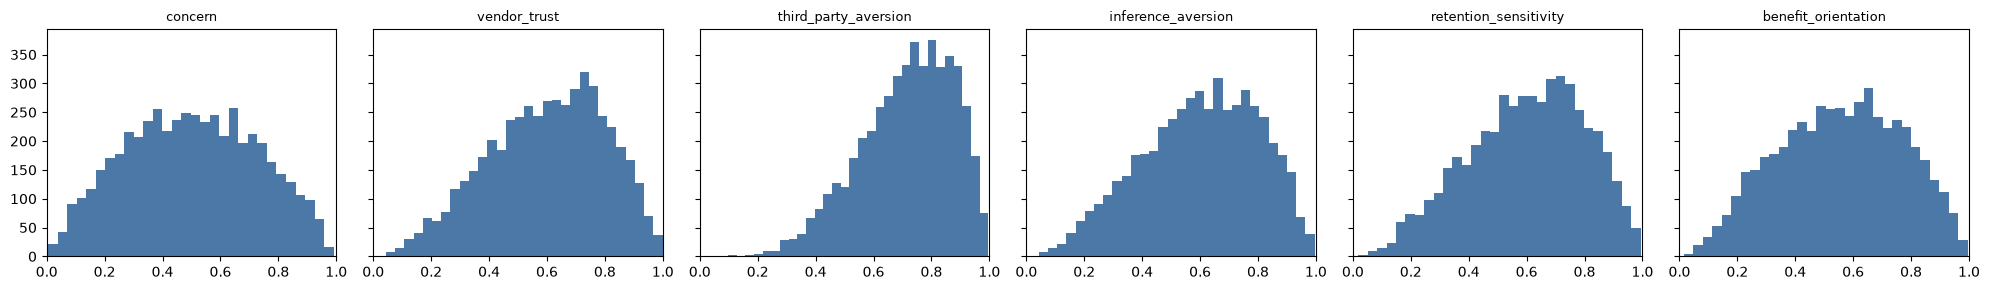

,concern,vendor_trust,third_party_aversion,inference_aversion,retention_sensitivity,benefit_orientation
concern,1.00,-0.33,0.34,0.36,0.27,-0.25
vendor_trust,-0.33,1.00,-0.01,-0.00,-0.01,0.01
third_party_aversion,0.34,-0.01,1.00,0.19,-0.01,-0.01
inference_aversion,0.36,-0.00,0.19,1.00,0.01,-0.01
retention_sensitivity,0.27,-0.01,-0.01,0.01,1.00,-0.01
benefit_orientation,-0.25,0.01,-0.01,-0.01,-0.01,1.00


In [5]:
corr = np.eye(len(TRAITS))
for (a, b), r in CONFIG["trait_correlation"].items():
    i, j = TRAITS.index(a), TRAITS.index(b)
    corr[i, j] = corr[j, i] = r
z = rng.multivariate_normal(np.zeros(len(TRAITS)), corr, size=n)        # 1
for fact, effects in CONFIG["fact_effects"].items():                     # 2
    std = (level[fact] - level[fact].mean()) / level[fact].std()
    for trait, w in effects.items():
        z[:, TRAITS.index(trait)] += w * std
z = (z - z.mean(axis=0)) / z.std(axis=0)
u = stats.norm.cdf(z)                                                     # 3
for i, name in enumerate(TRAITS):                                         # 4
    a, b = CONFIG["traits"][name]
    H[name] = stats.beta.ppf(u[:, i], a, b)

size_levels = CONFIG["facts"]["household_size"][0]
H["children"] = rng.random(n) < H.household_size.map(CONFIG["children_given_size"]).to_numpy()
print(f"children in {H.children.mean():.0%} of households")
fig, axes = plt.subplots(1, 6, figsize=(20, 3), sharey=True)
for ax, name in zip(axes, TRAITS):
    ax.hist(H[name], bins=30, color="#4c78a8"); ax.set_title(name, fontsize=9); ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()
H[TRAITS].corr().round(2)

## Step 3 · Sensitivity per data type, attitude per purpose

- **Sensitivity** to each of the 7 data types (0..1): the data type's base, shifted a little by concern, plus the
  household's own noise, plus a bonus for video and location when there are children.
- **Attitude** to each of the 8 purposes: the purpose's typical level, plus the household's **own deviation** for
  that purpose, plus a link to trust in the maker for analytics, personalization, ads and diagnostics. This is the
  main v2 change: households can now differ in *which* purposes they accept, not only in how strict they are.

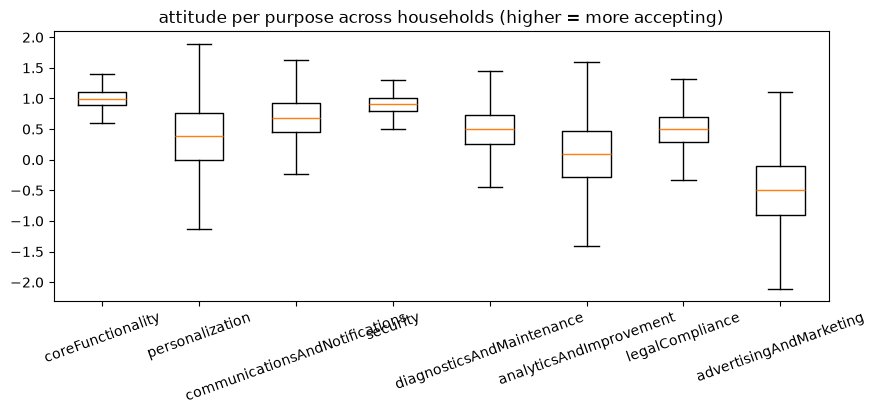

households accepting ads more than analytics: 24%


,coreFunctionality,personalization,communicationsAndNotifications,security,diagnosticsAndMaintenance,analyticsAndImprovement,legalCompliance,advertisingAndMarketing
coreFunctionality,1.00,0.01,-0.01,0.00,-0.00,-0.00,0.01,0.00
personalization,0.01,1.00,0.02,-0.01,0.02,0.04,0.00,0.01
communicationsAndNotifications,-0.01,0.02,1.00,-0.02,0.01,0.00,0.01,0.01
security,0.00,-0.01,-0.02,1.00,0.00,0.00,0.00,-0.00
diagnosticsAndMaintenance,-0.00,0.02,0.01,0.00,1.00,0.02,-0.02,0.04
analyticsAndImprovement,-0.00,0.04,0.00,0.00,0.02,1.00,-0.01,-0.00
legalCompliance,0.01,0.00,0.01,0.00,-0.02,-0.01,1.00,0.01
advertisingAndMarketing,0.00,0.01,0.01,-0.00,0.04,-0.00,0.01,1.00


In [6]:
base = np.array([CONFIG["data_type_sensitivity"][d] for d in DATA_TYPES])
shift = CONFIG["sensitivity_concern_shift"] * (H.concern.to_numpy() - 0.5)
sens = base[None, :] + shift[:, None] + rng.normal(0, CONFIG["sensitivity_noise_sd"], size=(n, len(DATA_TYPES)))
bonus = np.array([CONFIG["children_bonus"].get(d, 0.0) for d in DATA_TYPES])
sens = np.clip(sens + H.children.to_numpy()[:, None] * bonus[None, :], 0, 1)
for j, d in enumerate(DATA_TYPES):
    H[f"sens_{short(d)}"] = sens[:, j]

typical = np.array([CONFIG["purpose_typical"][p] for p in PURPOSES])
spread = np.array([CONFIG["purpose_spread"][p] for p in PURPOSES])
trust_link = np.array([CONFIG["purpose_trust_link"].get(p, 0.0) for p in PURPOSES])
att = typical[None, :] + rng.normal(0, 1, size=(n, len(PURPOSES))) * spread[None, :] + (H.vendor_trust.to_numpy() - 0.6)[:, None] * trust_link[None, :]
for j, p in enumerate(PURPOSES):
    H[f"att_{short(p)}"] = att[:, j]

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.boxplot([att[:, j] for j in range(len(PURPOSES))], tick_labels=[short(p) for p in PURPOSES], showfliers=False)
ax.set_title("attitude per purpose across households (higher = more accepting)"); plt.xticks(rotation=20); plt.show()
print(f"households accepting ads more than analytics: {(att[:, 7] > att[:, 5]).mean():.0%}")
pd.DataFrame(att, columns=[short(p) for p in PURPOSES]).corr().round(2)

## Step 4 · The decision on each item

For household *h* and item *i*:

```
u = intercept
    + benefit_weight × attitude[h, purpose] × (0.5 + benefit_orientation)               ← this household's view of the purpose
    − risk_weight × sensitivity[h, data type] × (0.7 + 0.6 × concern) × exposure          ← risk
    − source_term[source]
    + cell_noise[h, cell] + item_noise                                                     ← consistent within a cell

exposure = home_base + home_action_scale × action_term            if the flow stays home
         = away_base + recipient_term + action_term                otherwise
```

- `u ≥ 0` → **allow**.
- Otherwise, if a condition available for the item lifts `u` to ≥ 0 → **allow if** that condition, tried in the
  order *not kept*, *in-home only*, *on-device only* (conditions per item: notebook 01, §3). One PPD rule: `allow`
  with that qualifier in `constraints` (protocol-04 §7.11–7.12).
- Otherwise → **deny**.

### One household, one item, by hand

Household 7 and the real item *"camera video sent to the maker's cloud for remote viewing"* (Reolink):

In [7]:
def term(entry, hh):
    # base + weight * trait, for one household (a row) or all of them (the table)
    base, trait, weight = entry
    if trait:
        return base + weight * hh[trait]
    return base if isinstance(hh, pd.Series) else np.full(len(hh), base)

def find(data_type, purpose, action, source, context):
    q = (items.data_type == data_type) & (items.purpose == purpose) & (items.action == action) & (items.source == source) & (items.handling_context == context)
    return items[q].iloc[0]

h = 7
example = find("ppd:contentData", "ppd:coreFunctionality", "ppd:transfer", "ppd:participantGenerated", "ppd:vendorContext")
hh = H.loc[h]
s = hh[f"sens_{short(example.data_type)}"]
act, rec = term(CONFIG["action"][example.action], hh), term(CONFIG["recipient"][example.handling_context], hh)
exposure = CONFIG["home_base"] + CONFIG["home_action_scale"] * act if not example.leaves_home else CONFIG["away_base"] + rec + act
benefit_part = CONFIG["benefit_weight"] * hh[f"att_{short(example.purpose)}"] * (0.5 + hh.benefit_orientation)
risk_part = CONFIG["risk_weight"] * s * (CONFIG["concern_base"] + CONFIG["concern_scale"] * hh.concern) * exposure
source_part = CONFIG["source_term"][example.source]
pd.Series({"intercept": CONFIG["intercept"], "+ purpose attitude part": benefit_part, "- risk": -risk_part,
           "- source": -source_part, "= u before noise": CONFIG["intercept"] + benefit_part - risk_part - source_part}).round(3)

intercept                  0.900
+ purpose attitude part    0.975
- risk                    -2.343
- source                  -0.050
= u before noise          -0.518
dtype: float64

### All households, all items (in blocks of 1,000 households)

In [8]:
DENY, ALLOW, IF_EPHEMERAL, IF_IN_HOME, IF_ON_DEVICE = 0, 1, 2, 3, 4
DECISION_CODES = {0: "deny", 1: "allow", 2: "allow_if:retention=ppd:ephemeral",
                  3: "allow_if:processing_boundary=ppd:inHomeOnly", 4: "allow_if:processing_boundary=ppd:onDeviceOnly"}

recipient = np.stack([term(CONFIG["recipient"][c], H) for c in HANDLING_CONTEXTS], axis=1)
action = np.stack([term(CONFIG["action"][a], H) for a in ACTIONS], axis=1)
source = np.array([CONFIG["source_term"][s] for s in SOURCES])
d_idx = items.data_type.map(DATA_TYPES.index).to_numpy()
p_idx = items.purpose.map(PURPOSES.index).to_numpy()
a_idx = items.action.map(ACTIONS.index).to_numpy()
s_idx = items.source.map(SOURCES.index).to_numpy()
c_idx = items.handling_context.map(HANDLING_CONTEXTS.index).to_numpy()
cell_idx = items.cell_id.to_numpy()
home = ~items.leaves_home.to_numpy()
boundary_ok = items.action.isin(["ppd:use", "ppd:inference"]).to_numpy()
concern, orient, retention = H.concern.to_numpy(), H.benefit_orientation.to_numpy(), H.retention_sensitivity.to_numpy()

m = len(items)
D = np.zeros((n, m), dtype=np.uint8)
for start in range(0, n, 1000):
    sl = slice(start, min(start + 1000, n)); k = sl.stop - sl.start
    s_h, act, rec = sens[sl][:, d_idx], action[sl][:, a_idx], recipient[sl][:, c_idx]
    exposure = np.where(home[None, :], CONFIG["home_base"] + CONFIG["home_action_scale"] * act, CONFIG["away_base"] + rec + act)
    scale = CONFIG["risk_weight"] * s_h * (CONFIG["concern_base"] + CONFIG["concern_scale"] * concern[sl, None])
    noise = rng.normal(0, CONFIG["cell_noise_sd"], size=(k, N_CELLS))[:, cell_idx] + rng.normal(0, CONFIG["item_noise_sd"], size=(k, m))
    u = (CONFIG["intercept"]
         + CONFIG["benefit_weight"] * att[sl][:, p_idx] * (0.5 + orient[sl, None])
         - scale * exposure
         - source[s_idx][None, :]
         + noise)
    gain_ephemeral = CONFIG["ephemeral_gain"] * retention[sl, None] * s_h * np.where(home, CONFIG["ephemeral_home_scale"], 1.0)[None, :]
    away_part = np.where(home[None, :], 0.0, rec)
    gain_in_home = np.where(boundary_ok[None, :], scale * CONFIG["in_home_removes"] * away_part, -np.inf)
    gain_on_device = np.where(boundary_ok[None, :], scale * CONFIG["on_device_removes"] * (away_part + np.where(home, CONFIG["home_base"], 0.0)[None, :]), -np.inf)
    d = np.full(u.shape, DENY, dtype=np.uint8)     # later lines win: allow beats every condition,
    d[(u + gain_on_device) >= 0] = IF_ON_DEVICE    # "not kept" is tried before in-home, in-home before on-device
    d[(u + gain_in_home) >= 0] = IF_IN_HOME
    d[(u + gain_ephemeral) >= 0] = IF_EPHEMERAL
    d[u >= 0] = ALLOW
    D[sl] = d

print(f"{D.size:,} decisions; household {h} on the example item: {DECISION_CODES[int(D[h, example.item_id])]}")
pd.Series({DECISION_CODES[k]: (D == k).mean() for k in DECISION_CODES}).map("{:.1%}".format).rename("share")

31,360,000 decisions; household 7 on the example item: allow_if:retention=ppd:ephemeral


deny                                             26.1%
allow                                            56.7%
allow_if:retention=ppd:ephemeral                  7.8%
allow_if:processing_boundary=ppd:inHomeOnly       6.9%
allow_if:processing_boundary=ppd:onDeviceOnly     2.5%
Name: share, dtype: str

## Step 5 · Checks

1. The effects point the way the studies say.
2. v2's goals hold: purposes vary independently between households; no single pattern dominates the data.

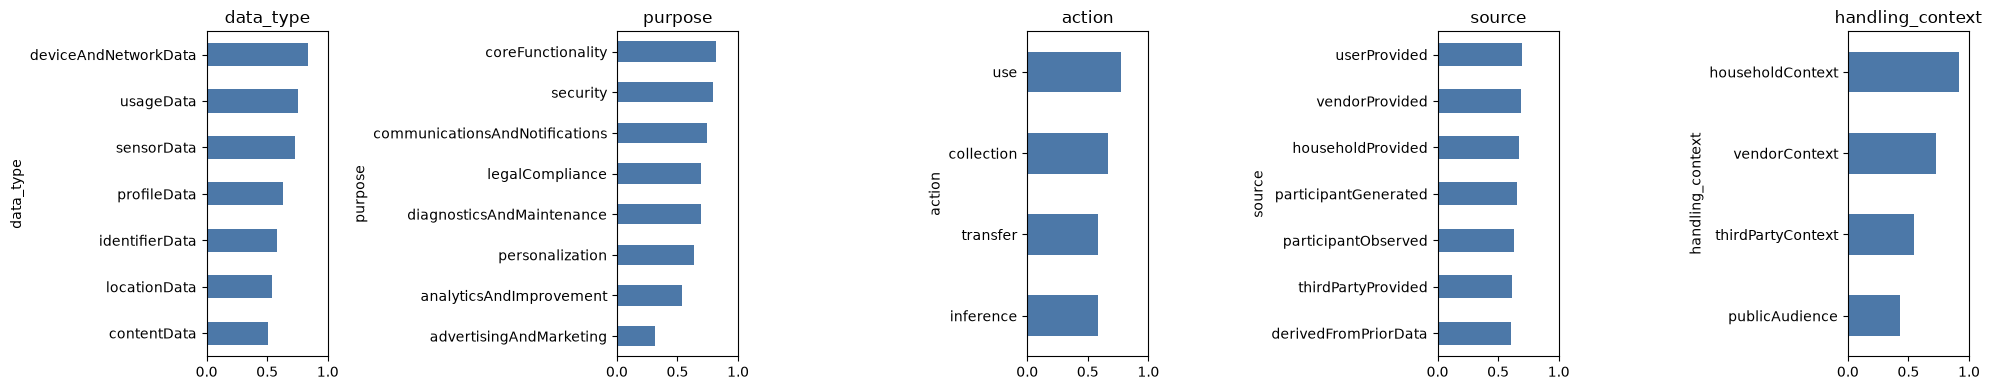

variance explained by the first 5 patterns: [0.176 0.094 0.063 0.047 0.033]


video (content) is the least accepted data type (N17)      True
advertising is the least accepted purpose                  True
staying home is the most accepted                          True
third parties below the maker (N21)                        True
inference below use (N17)                                  True
more concern, less acceptance                              True
more devices, more acceptance (S20: more apps used)        True
purpose attitudes vary independently (|r| < 0.5)           True
some households accept ads more than analytics (10-90%)    True
no single pattern dominates (PC1 < 25%)                    True
Name: holds, dtype: bool

In [9]:
ORDINAL = np.array([0.0, 1.0, 0.5, 0.5, 0.5], dtype=np.float32)
V = ORDINAL[D]
item_mean = pd.Series(V.mean(axis=0))
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, f in zip(axes, FIELDS):
    item_mean.groupby(items[f].map(short)).mean().sort_values().plot.barh(ax=ax, color="#4c78a8")
    ax.set_xlim(0, 1); ax.set_title(f)
plt.tight_layout(); plt.show()

# How much of the variation the biggest single pattern explains (v1: 35%).
from sklearn.decomposition import PCA
pc1 = PCA(5, random_state=0).fit(V).explained_variance_ratio_
perm = V.mean(axis=1)
purpose_corr = np.corrcoef(att[:, [5, 1, 7]].T)   # analytics, personalization, ads
checks = {
    "video (content) is the least accepted data type (N17)": item_mean.groupby(items.data_type).mean().idxmin() == "ppd:contentData",
    "advertising is the least accepted purpose": item_mean.groupby(items.purpose).mean().idxmin() == "ppd:advertisingAndMarketing",
    "staying home is the most accepted": item_mean.groupby(items.handling_context).mean().idxmax() == "ppd:householdContext",
    "third parties below the maker (N21)": item_mean[items.handling_context == "ppd:thirdPartyContext"].mean() < item_mean[items.handling_context == "ppd:vendorContext"].mean(),
    "inference below use (N17)": item_mean[items.action == "ppd:inference"].mean() < item_mean[items.action == "ppd:use"].mean(),
    "more concern, less acceptance": np.corrcoef(concern, perm)[0, 1] < -0.4,
    "more devices, more acceptance (S20: more apps used)": np.corrcoef(level["devices"], perm)[0, 1] > 0.05,
    "purpose attitudes vary independently (|r| < 0.5)": np.abs(purpose_corr[np.triu_indices(3, 1)]).max() < 0.5,
    "some households accept ads more than analytics (10-90%)": 0.1 < (att[:, 7] > att[:, 5]).mean() < 0.9,
    "no single pattern dominates (PC1 < 25%)": pc1[0] < 0.25,
}
assert all(checks.values()), checks
print("variance explained by the first 5 patterns:", pc1.round(3))
pd.Series(checks, name="holds")

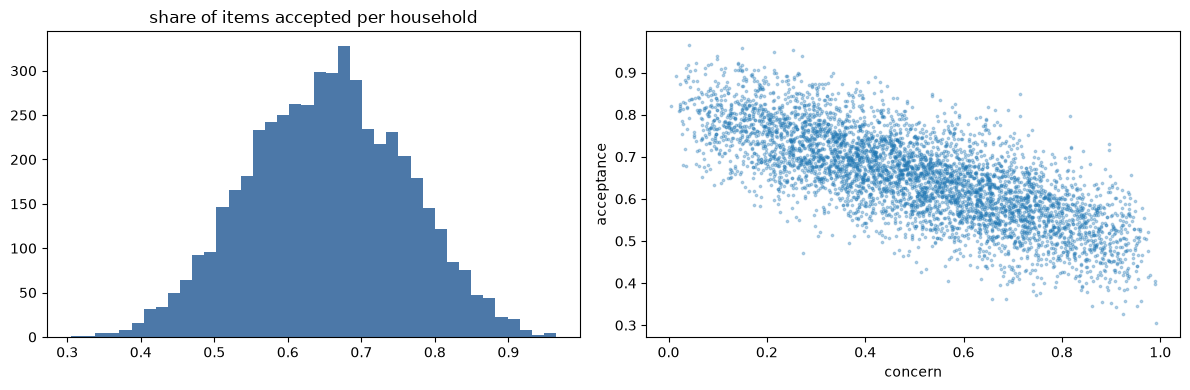

acceptance quantiles (0, 10, 50, 90, 100%): [0.31 0.51 0.65 0.79 0.96]


In [10]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
a.hist(perm, bins=40, color="#4c78a8"); a.set_title("share of items accepted per household")
b.scatter(H.concern, perm, s=3, alpha=0.3); b.set_xlabel("concern"); b.set_ylabel("acceptance")
plt.tight_layout(); plt.show()
print("acceptance quantiles (0, 10, 50, 90, 100%):", np.quantile(perm, [0, .1, .5, .9, 1]).round(2))

## Step 6 · Answers to the candidate onboarding questions (27)

| Group | Questions | Comes from |
| --- | --- | --- |
| Household facts | `devices`, `household_size`, `age_band`, `children` | the facts, answered exactly (S20 used background facts in its profiling trees) |
| General | `concern`, `trust_maker` (1–5) | their trait + noise. Ours, not from the app; S20 left a general privacy-attitude scale out as not predictive, so these are candidates only |
| Data (app Q2 rows) | `data_content`, `data_location`, `data_identity`, `data_sensor`, `data_usage`, `data_network` | that data type's sensitivity + noise (no longer concern directly) |
| Purposes (app Q3 rows) | `purpose_core`, `_comms`, `_diag`, `_analytics`, `_personal`, `_ads` | that purpose's own attitude + noise |
| Recipient / action / retention (app Q4–Q6) | `sharing`, `inference`, `retention` | their trait + noise |
| **Concrete** (new) | 6 questions about flows real devices declare, worded generically (no product names) | the household's **own decision** on that item; with chance `concrete_answer_slip` the answer is something else |

The app's Q3 does not cover `ppd:security` or `ppd:legalCompliance`; here security is grouped with "making a feature
work" and legal duties with "fixing problems". Q7 (notifications) is left out because it sets no rules.

In [11]:
THREE = ["never", "ask", "fine"]
DATA_GROUPS = {
    "content": (["ppd:contentData"], "Video, photos and sound"),
    "location": (["ppd:locationData"], "Where you are"),
    "identity": (["ppd:identifierData", "ppd:profileData"], "Who you are (accounts, names, profile)"),
    "sensor": (["ppd:sensorData"], "Sensor readings (temperature, motion, …)"),
    "usage": (["ppd:usageData"], "How you use the device"),
    "network": (["ppd:deviceAndNetworkData"], "Device and network details"),
}
PURPOSE_GROUPS = {
    "core": (["ppd:coreFunctionality", "ppd:security"], "Making a feature work, keeping it secure"),
    "comms": (["ppd:communicationsAndNotifications"], "Sending you alerts and messages"),
    "diag": (["ppd:diagnosticsAndMaintenance", "ppd:legalCompliance"], "Fixing problems, legal duties"),
    "analytics": (["ppd:analyticsAndImprovement"], "Improving their products"),
    "personal": (["ppd:personalization"], "Personalizing what you see"),
    "ads": (["ppd:advertisingAndMarketing"], "Advertising and marketing"),
}
# Each concrete question is one real-device flow (notebook 01 corpus), worded generically: the flow is a type of data
# flow any device can have, so the question does not assume the household owns that product.
CONCRETE = {
    "real_video_cloud": (("ppd:contentData", "ppd:coreFunctionality", "ppd:transfer", "ppd:participantGenerated", "ppd:vendorContext"),
                         "Would you let a device send video or audio from your home to its maker's cloud, so you can use it remotely?"),
    "real_location_home_away": (("ppd:locationData", "ppd:coreFunctionality", "ppd:collection", "ppd:participantObserved", "ppd:vendorContext"),
                                "Would you let a device's maker use your phone's location to know when you are home or away?"),
    "real_usage_improve": (("ppd:usageData", "ppd:analyticsAndImprovement", "ppd:transfer", "ppd:participantGenerated", "ppd:vendorContext"),
                           "Would you let a device send how you use it to its maker to improve their products?"),
    "real_profile_ads": (("ppd:profileData", "ppd:advertisingAndMarketing", "ppd:use", "ppd:derivedFromPriorData", "ppd:vendorContext"),
                         "Would you let a device's maker use a profile of how you use it to show you ads?"),
    "real_viewing_advertisers": (("ppd:usageData", "ppd:advertisingAndMarketing", "ppd:transfer", "ppd:vendorProvided", "ppd:thirdPartyContext"),
                                 "Would you let a device's maker share how you use it with advertisers?"),
    # Added last (so every other answer stays identical): the one real personalization flow (Aqara "Follow Presence").
    # It lets onboarding recognise households that dislike personalization (notebook 05).
    "real_personalized_heating": (("ppd:sensorData", "ppd:personalization", "ppd:use", "ppd:derivedFromPriorData", "ppd:householdContext"),
                                  "Would you let a smart device use who is home and readings from your home to personalize how it works, without the data leaving your home?"),
}
CONCRETE_OPTIONS = ["no", "with_limits", "yes"]
QUESTIONS = [
    {"id": "devices", "text": "How many smart devices are in your home?", "options": CONFIG["facts"]["devices"][0], "from": "fact"},
    {"id": "household_size", "text": "How many people live in your home?", "options": CONFIG["facts"]["household_size"][0], "from": "fact"},
    {"id": "age_band", "text": "What is your age?", "options": CONFIG["facts"]["age_band"][0], "from": "fact"},
    {"id": "children", "text": "Do children live in your home, or visit often?", "options": ["yes", "no"], "from": "fact (app Q1)"},
    {"id": "concern", "text": "How much do you worry about what smart devices do with your data?", "options": list("12345"), "from": "concern (ours)"},
    {"id": "trust_maker", "text": "How much do you trust device makers with your data?", "options": list("12345"), "from": "vendor_trust (ours)"},
    *[{"id": f"data_{k}", "text": f"{label}: may it leave your home?", "options": THREE, "from": f"sensitivity to {', '.join(map(short, t))} (app Q2)"} for k, (t, label) in DATA_GROUPS.items()],
    *[{"id": f"purpose_{k}", "text": f"May companies use your data for: {label.lower()}?", "options": THREE, "from": f"attitude to {', '.join(map(short, t))} (app Q3)"} for k, (t, label) in PURPOSE_GROUPS.items()],
    {"id": "sharing", "text": "May a device's maker pass your data to other companies?", "options": ["never", "ask", "features"], "from": "third_party_aversion (app Q4)"},
    {"id": "inference", "text": "May companies work out extra things about you from your data?", "options": ["never", "ask", "ok"], "from": "inference_aversion (app Q5)"},
    {"id": "retention", "text": "How long may companies keep your data?", "options": ["briefly", "ask", "any"], "from": "retention_sensitivity (app Q6)"},
    *[{"id": k, "text": text, "options": CONCRETE_OPTIONS, "from": "own decision on a real item"} for k, (_, text) in CONCRETE.items()],
]
pd.DataFrame(QUESTIONS).set_index("id")[["text", "from"]]

,text,from
id,,
devices,How many smart devices are in your home?,fact
household_size,How many people live in your home?,fact
age_band,What is your age?,fact
children,"Do children live in your home, or visit often?",fact (app Q1)
concern,How much do you worry about what smart devices...,concern (ours)
trust_maker,How much do you trust device makers with your ...,vendor_trust (ours)
data_content,"Video, photos and sound: may it leave your home?",sensitivity to contentData (app Q2)
data_location,Where you are: may it leave your home?,sensitivity to locationData (app Q2)
data_identity,"Who you are (accounts, names, profile): may it...","sensitivity to identifierData, profileData (ap..."


In [12]:
answer_rng = np.random.default_rng(CONFIG["seed"] + 1)   # a separate stream, so answers don't shift the decisions
noise = lambda: answer_rng.normal(0, CONFIG["answer_noise_sd"], n)

def three(score, low, high, labels=THREE):      # 0..1, higher = more permissive
    return np.where(score < low, labels[0], np.where(score > high, labels[2], labels[1]))

def likert(score):                              # 0..1 -> "1".."5"
    return np.clip(np.rint(1 + 4 * score), 1, 5).astype(int).astype(str)

A = pd.DataFrame({"household_id": H.household_id})
for fact in CONFIG["facts"]:
    A[fact] = H[fact]
A["children"] = np.where(H.children, "yes", "no")
A["concern"] = likert(np.clip(concern + noise(), 0, 1))
A["trust_maker"] = likert(np.clip(H.vendor_trust.to_numpy() + noise(), 0, 1))
for key, (terms, _) in DATA_GROUPS.items():
    s = H[[f"sens_{short(t)}" for t in terms]].to_numpy().mean(axis=1)
    A[f"data_{key}"] = three(1 - s + noise(), 0.35, 0.65)
for key, (terms, _) in PURPOSE_GROUPS.items():
    a = H[[f"att_{short(t)}" for t in terms]].to_numpy().mean(axis=1)
    A[f"purpose_{key}"] = three(0.5 + 0.35 * a + noise(), 0.45, 0.75)
A["sharing"] = three(1 - H.third_party_aversion.to_numpy() + noise(), 0.3, 0.6, ["never", "ask", "features"])
A["inference"] = three(1 - H.inference_aversion.to_numpy() + noise(), 0.3, 0.6, ["never", "ask", "ok"])
A["retention"] = three(1 - H.retention_sensitivity.to_numpy() + noise(), 0.3, 0.6, ["briefly", "ask", "any"])
for key, (fields, _) in CONCRETE.items():
    own = D[:, find(*fields).item_id]
    truth = np.where(own == ALLOW, "yes", np.where(own == DENY, "no", "with_limits"))
    slip = answer_rng.random(n) < CONFIG["concrete_answer_slip"]
    A[key] = np.where(slip, answer_rng.choice(CONCRETE_OPTIONS, size=n), truth)

for q in QUESTIONS:
    assert set(A[q["id"]]) <= set(q["options"]), q["id"]
pd.DataFrame({q["id"]: A[q["id"]].value_counts(normalize=True).round(2).to_dict() for q in QUESTIONS}).T.astype(object).fillna("")

,4-7,8-15,1-3,16+,2,3-4,1,5+,45-64,30-44,...,4,5,never,ask,fine,features,ok,briefly,any,with_limits
devices,0.36,0.27,0.26,0.12,,,,,,,...,,,,,,,,,,
household_size,,,,,0.35,0.29,0.28,0.08,,,...,,,,,,,,,,
age_band,,,,,,,,,0.32,0.27,...,,,,,,,,,,
children,,,,,,,,,,,...,,,,,,,,,,
concern,,,,,0.23,,0.11,,,,...,0.23,0.11,,,,,,,,
trust_maker,,,,,0.17,,0.05,,,,...,0.3,0.17,,,,,,,,
data_content,,,,,,,,,,,...,,,0.8,0.18,0.03,,,,,
data_location,,,,,,,,,,,...,,,0.69,0.26,0.05,,,,,
data_identity,,,,,,,,,,,...,,,0.51,0.39,0.11,,,,,
data_sensor,,,,,,,,,,,...,,,0.23,0.41,0.36,,,,,


### How each answer relates to each trait

Rank correlation between traits/attitudes and answers (answers coded so higher = more permissive; aversions and
sensitivities show as negative). In v2 each data and purpose question should track **its own** sensitivity or
attitude, with concern bleeding in much less than in v1 (−0.35 to −0.66 there).

In [13]:
codes = {"never": 0, "ask": 1, "fine": 2, "features": 2, "ok": 2, "briefly": 0, "any": 2, "no": 0, "yes": 1, "with_limits": 0.5}
order = {fact: {v: i for i, v in enumerate(CONFIG["facts"][fact][0])} for fact in CONFIG["facts"]}
num = A.drop(columns="household_id").apply(lambda c: pd.to_numeric(c.map(order.get(c.name, codes)) if c.name in order else c.map(lambda v: codes.get(v, v))))
num["children"] = (A.children == "yes").astype(int)
cols = TRAITS + [c for c in H.columns if c.startswith(("sens_", "att_"))]
table = pd.DataFrame({q: [num[q].corr(H[c], method="spearman") for c in cols] for q in num.columns}, index=cols).T.round(2)
own = {f"data_{k}": f"sens_{short(t[0])}" for k, (t, _) in DATA_GROUPS.items()} | {f"purpose_{k}": f"att_{short(t[0])}" for k, (t, _) in PURPOSE_GROUPS.items()}
summary = pd.DataFrame({"own trait": {q: table.loc[q, c] for q, c in own.items()}, "concern": {q: table.loc[q, "concern"] for q in own}})
assert (summary["own trait"].abs() > summary["concern"].abs()).all(), "a data/purpose question tracks concern more than its own trait"
display(summary)
table

,own trait,concern
data_content,-0.47,-0.09
data_location,-0.54,-0.10
data_identity,-0.34,-0.11
data_sensor,-0.61,-0.10
data_usage,-0.60,-0.13
data_network,-0.55,-0.10
purpose_core,0.10,0.01
purpose_comms,0.46,-0.02
purpose_diag,0.23,-0.00
purpose_analytics,0.62,-0.01


,concern,vendor_trust,third_party_aversion,inference_aversion,retention_sensitivity,benefit_orientation,sens_identifierData,sens_profileData,sens_sensorData,sens_contentData,...,sens_deviceAndNetworkData,sens_usageData,att_coreFunctionality,att_personalization,att_communicationsAndNotifications,att_security,att_diagnosticsAndMaintenance,att_analyticsAndImprovement,att_legalCompliance,att_advertisingAndMarketing
devices,-0.22,0.14,0.00,-0.01,-0.02,0.19,-0.05,-0.04,-0.04,-0.03,...,-0.06,-0.04,-0.01,0.03,0.03,-0.02,0.02,-0.00,-0.01,0.02
household_size,-0.01,0.02,-0.01,-0.03,0.00,-0.01,0.00,-0.00,0.02,0.21,...,-0.01,0.01,0.01,0.00,0.01,-0.01,-0.01,0.00,0.00,-0.00
age_band,0.16,-0.07,0.03,0.04,0.00,-0.10,0.06,0.02,0.04,0.01,...,0.02,0.05,0.00,-0.01,-0.01,-0.01,0.00,-0.02,-0.01,0.01
children,0.02,-0.01,-0.01,-0.01,0.02,0.00,0.01,0.03,0.02,0.34,...,0.00,0.00,-0.02,0.00,0.02,-0.01,-0.03,-0.00,-0.00,-0.02
concern,0.73,-0.22,0.25,0.25,0.19,-0.19,0.15,0.13,0.14,0.11,...,0.12,0.14,0.03,-0.06,-0.03,-0.01,-0.02,-0.02,0.01,-0.02
trust_maker,-0.22,0.68,-0.00,-0.02,-0.00,0.01,-0.03,-0.04,-0.04,-0.06,...,-0.04,-0.05,0.00,0.11,0.02,0.00,0.09,0.13,-0.01,0.08
data_content,-0.09,0.02,-0.02,-0.01,-0.03,-0.01,-0.03,-0.02,-0.01,-0.47,...,-0.03,-0.01,0.01,0.02,-0.01,-0.01,0.04,0.01,0.01,0.03
data_location,-0.10,0.02,-0.02,-0.01,-0.02,0.03,-0.01,-0.03,-0.04,-0.06,...,-0.02,-0.00,-0.00,0.01,0.01,0.02,0.01,0.01,-0.03,0.00
data_identity,-0.11,0.05,-0.05,-0.03,-0.03,0.03,-0.34,-0.36,-0.02,-0.04,...,-0.02,-0.04,-0.01,-0.00,0.01,-0.01,0.02,0.02,-0.02,0.01
data_sensor,-0.10,0.01,-0.04,-0.04,-0.04,0.02,-0.01,-0.00,-0.61,-0.04,...,-0.03,-0.03,-0.02,0.03,0.02,-0.02,0.01,0.03,-0.00,-0.03


## Step 7 · Save

- `data/households.csv` (facts, traits, sensitivities, purpose attitudes), `data/answers.csv`, `data/questions.json` (question texts and option order), `data/decisions.npy`
  (uint8, codes in `decision_codes.json`), `data/cells.csv` and `data/decisions_cells.npy` (each household's average
  acceptance per cell, for clustering) — gitignored;
- `data/sample/`: the first 200 households, and their decisions on the 52 real-device items in readable form — committed;
- `data/DATACARD.md`, including a SHA-256 of the decisions: same notebooks + seed ⇒ same hash.

In [14]:
DATA.mkdir(exist_ok=True)
H.to_csv(DATA / "households.csv", index=False, float_format="%.4f")
A.to_csv(DATA / "answers.csv", index=False)
(DATA / "questions.json").write_text(json.dumps(QUESTIONS, indent=2) + "\n")   # texts and option order, for notebook 05
np.save(DATA / "decisions.npy", D)
(DATA / "decision_codes.json").write_text(json.dumps({str(k): v for k, v in DECISION_CODES.items()}, indent=2) + "\n")
cells.to_csv(DATA / "cells.csv", index=False)
cell_means = np.stack([V[:, cell_idx == c].mean(axis=1) for c in cells.cell_id], axis=1).astype(np.float32)
np.save(DATA / "decisions_cells.npy", cell_means)

sample = DATA / "sample"; sample.mkdir(exist_ok=True)
ids = list(range(200))
H.iloc[ids].to_csv(sample / "households.csv", index=False, float_format="%.4f")
A.iloc[ids].to_csv(sample / "answers.csv", index=False)
np.save(sample / "decisions.npy", D[ids])
real = items[items.in_corpus]
long = pd.DataFrame([(hid, i, DECISION_CODES[int(D[hid, i])]) for hid in ids for i in real.item_id],
                    columns=["household_id", "item_id", "decision"]).merge(items[["item_id", *FIELDS]], on="item_id")
long.to_csv(sample / "decisions_corpus_items.csv", index=False)

sha = hashlib.sha256(D.tobytes()).hexdigest()
shares = "\n".join(f"| `{v}` | {(D == k).mean():.1%} |" for k, v in DECISION_CODES.items())
(DATA / "DATACARD.md").write_text(f'''# Data card: synthetic PPD household preferences (v2)

Generated {date.today().isoformat()} by `notebooks/02_generate_households.ipynb` (seed {CONFIG['seed']}); items from
`notebooks/01_items.ipynb`. Same notebooks and seed reproduce the same data (SHA-256 below).

## What it is

{n:,} synthetic households: facts (smart devices, household size, age band, children), six general traits, a sensitivity
per data type, an attitude per purpose; their decision on each of the {m:,} core PPD dataflows (data type x purpose x
action x source x handling context, draft-dsmullen-ppd-taxonomy-05 section 6); their answers to {len(QUESTIONS)} candidate
onboarding questions.

**This is not survey data.** Decisions follow from traits and weights chosen in notebook 02; directions come from
Emami-Naeini et al. 2017, 2020, 2021 and Smullen et al. 2020; magnitudes are ours. Use it to build and test the
pipeline, not to claim how real households behave. Why one decision per 5-field combination and why qualifiers are
conditions inside a decision: notebook 01 and README.md ("How this follows the PPD drafts").

## Files

| File | Contents |
| --- | --- |
| `items.csv` | the {m:,} items with flags (notebook 01) |
| `cells.csv` | the {N_CELLS} cells (data type x purpose x handling context) |
| `households.csv` | household_id, facts, 6 traits (0..1), children, sensitivity per data type (`sens_*`), attitude per purpose (`att_*`) |
| `answers.csv` | household_id, one column per question |
| `decisions.npy` | uint8 [households x items]; codes in `decision_codes.json` |
| `decisions_cells.npy` | float32 [households x cells]: average acceptance (deny 0, allow-if 0.5, allow 1) per cell |
| `sample/` | the first 200 households; their decisions on the {len(real)} real-device items, readable (committed) |

{int(items.in_corpus.sum())} of {m:,} items are declared by the researched devices; {int(items.plausible.sum()):,} pass the plausibility
check. Nothing is filtered out.

## Decision shares

| Decision | Share |
| --- | --- |
{shares}

First 5 patterns (PCA) explain {', '.join(f'{x:.0%}' for x in pc1)} of the variation (v1: 35% for the first alone).

Decisions SHA-256: `{sha}`

## Known limits

- Weights are our reading of the literature; a planned sensitivity notebook varies them.
- Answers come from the same household as decisions (answer noise {CONFIG['answer_noise_sd']}, concrete slip {CONFIG['concrete_answer_slip']});
  real people are less consistent.
- "Ask" is never a decision (PPD effects are allow and deny); it appears only as an answer.
- One condition per cell (a rule may carry several qualifiers); jurisdiction is not modelled.
''')
print("decisions SHA-256:", sha)

decisions SHA-256: c53896e7878d69544826d7e1509e4b41882a3411b95abe12917ae411b9b7b213
